Need to download the credit card data set from Kaggle and explore it.

Part 1. [10 pts] Explore the dataset, list the number of rows and columns, check sanity, and 
examine the features (e.g. with histograms or plots).

In [1]:
#file path
file_path = r"C:\Users\jbosb\OneDrive\Documents\Hopkins_Studies\Applied_Machine_Learning\creditcard.csv\creditcard.csv"
#read in file
import pandas as pd
cc_data = pd.read_csv(file_path)
#look at headers and shape
print(cc_data.head())
print(cc_data.shape)

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

Pretty extensive file, 284,807 rows with 30 features and 1 Class. Next up sanity check.


In [2]:
#need to check for infinite, NaN and other weird values
import numpy as np
#check feature types
print(cc_data.dtypes)
print(cc_data.isnull().sum())
print(cc_data.isin([np.inf, -np.inf]).sum())

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64
Time      0
V1        0
V2        0
V3     

Looks like nothing unusual in the data set. Check out correlations. Convert the dtype for the features from float64 to float32, that will make running the models go faster

In [3]:
#convert all features except for Class to float32, this will help with scaling and modeling
for col in cc_data.columns:
    if col != "Class":
        cc_data[col] = cc_data[col].astype(np.float32)
        

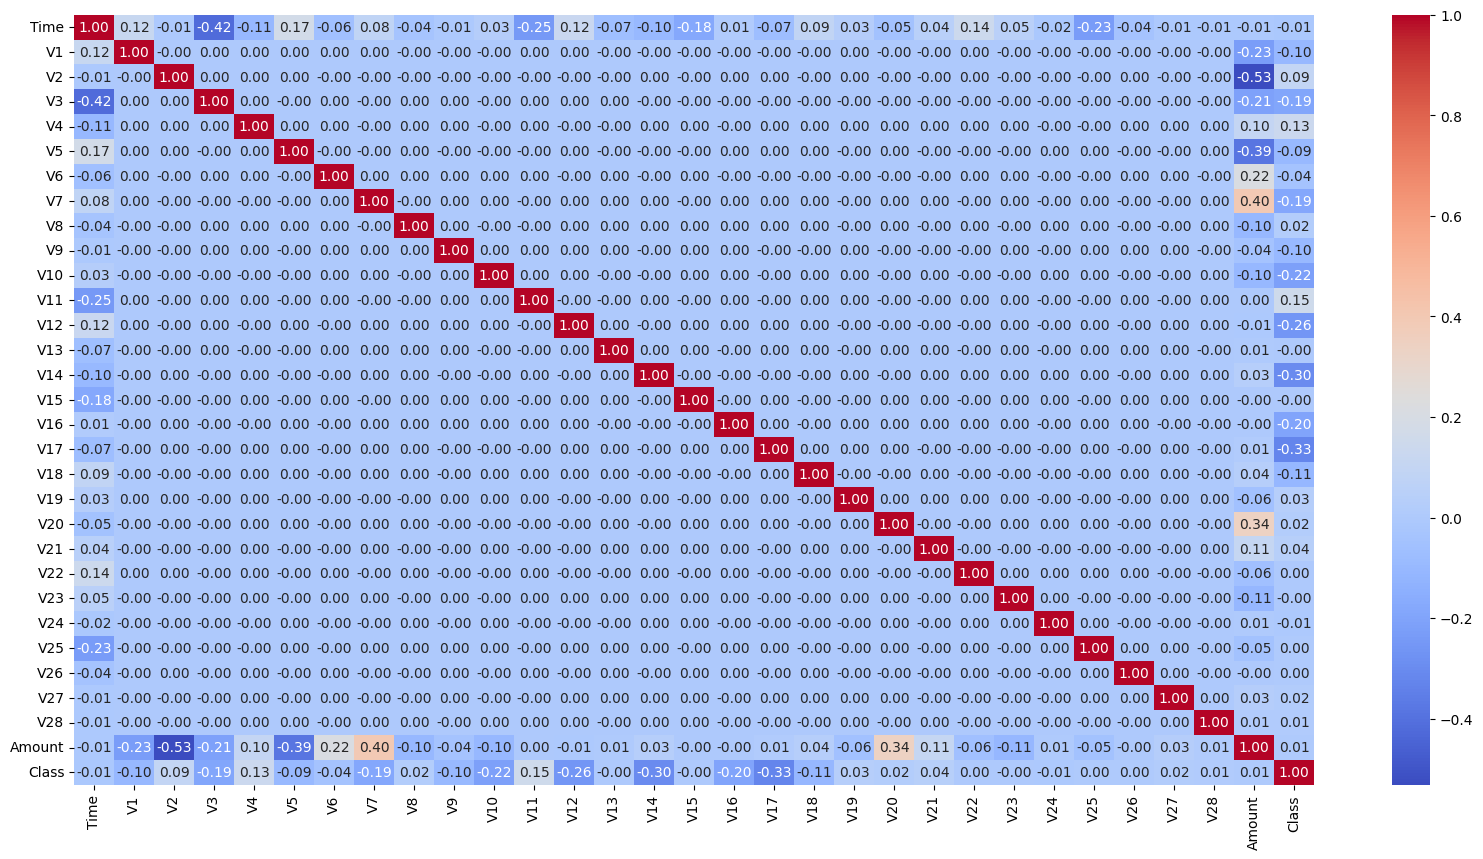

In [4]:
#need to check correlations with a heat map, I know this will be convuluted but I need to see it
import seaborn as sns
import matplotlib.pyplot as plt
#do not include the class labbel in numerical features for correlation
numeric_features = cc_data.select_dtypes(include=[np.number]).columns.tolist()
numeric_features.remove("Class")
correlation_matrix = cc_data[numeric_features + ["Class"]].corr()
plt.figure(figsize=(20, 10))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

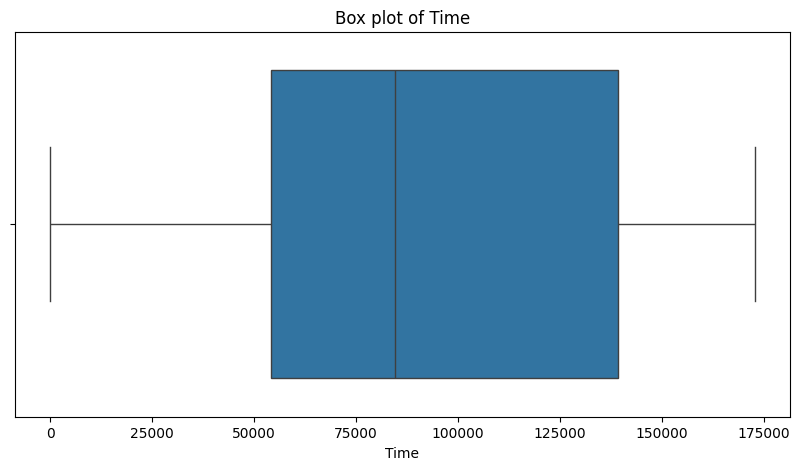

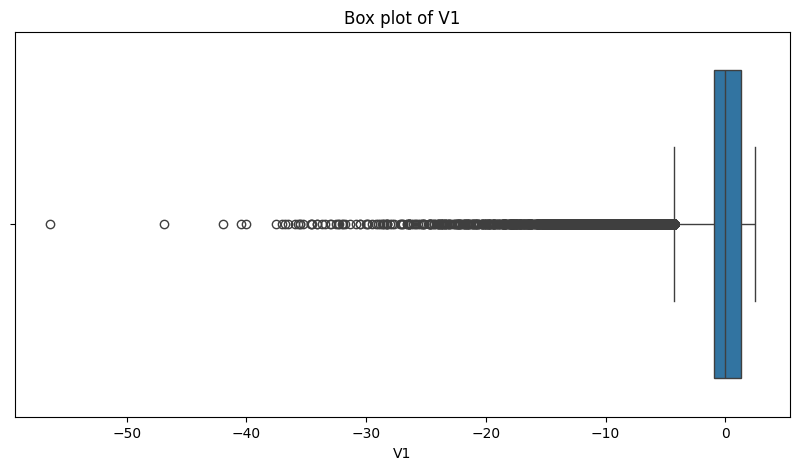

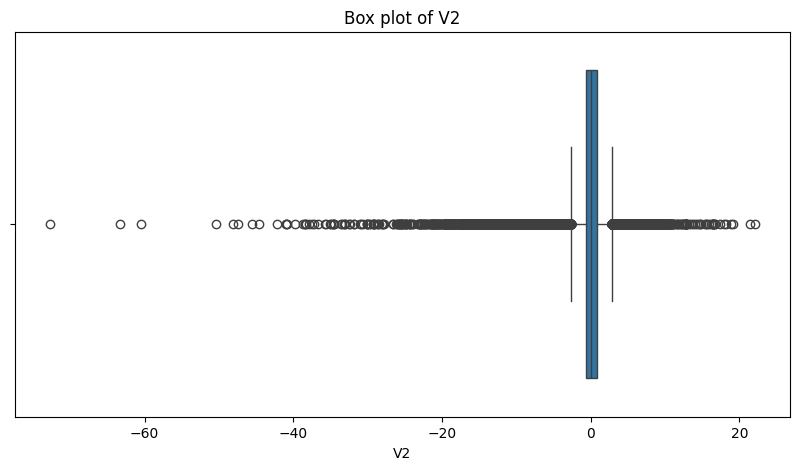

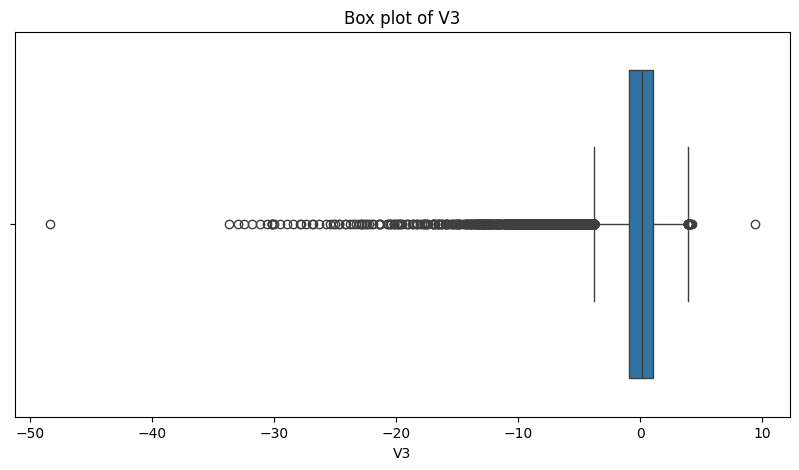

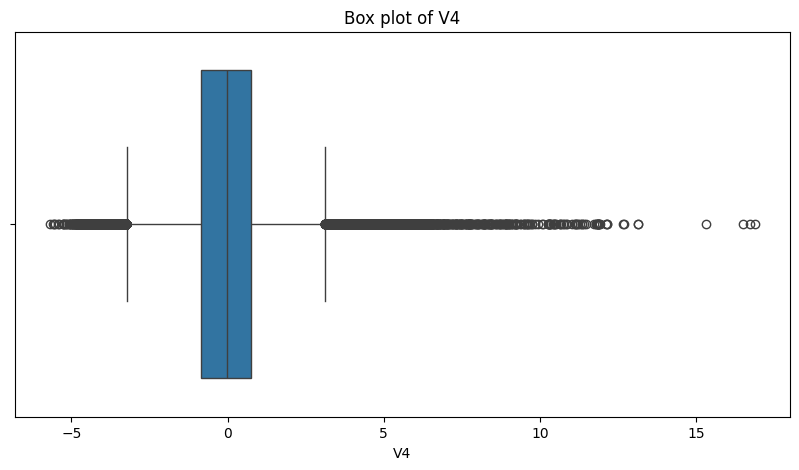

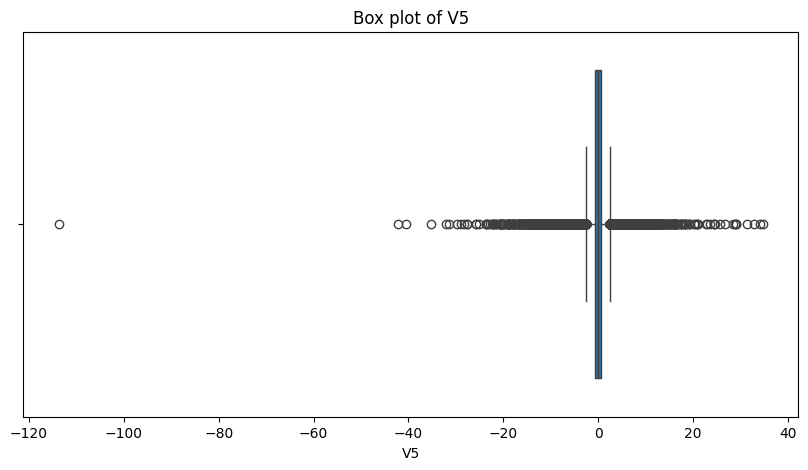

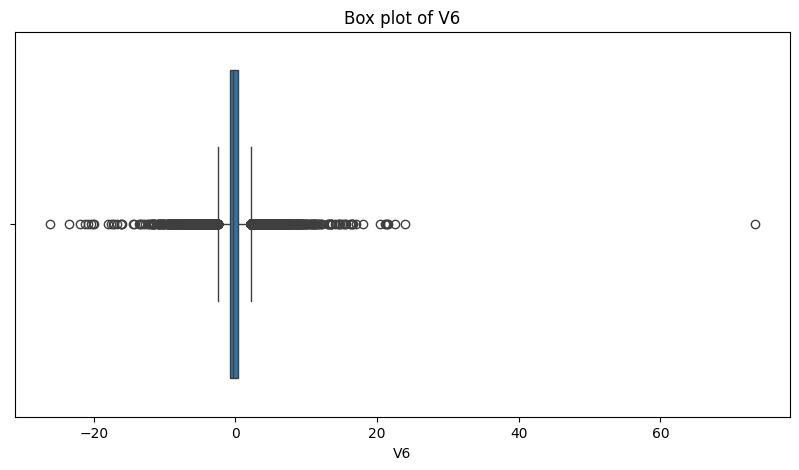

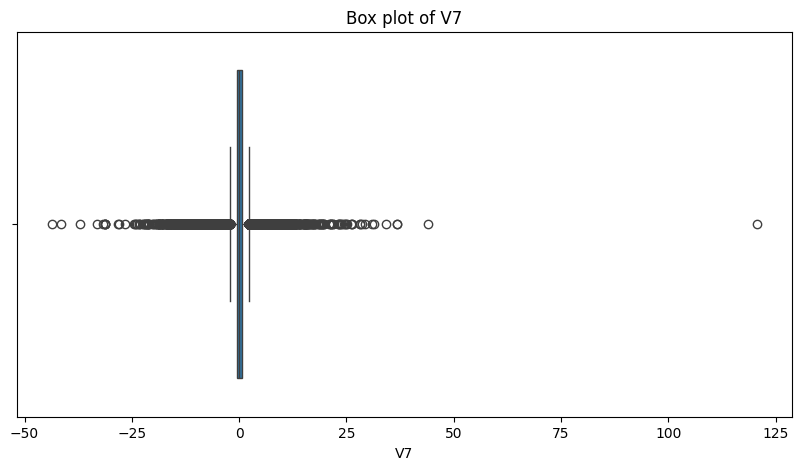

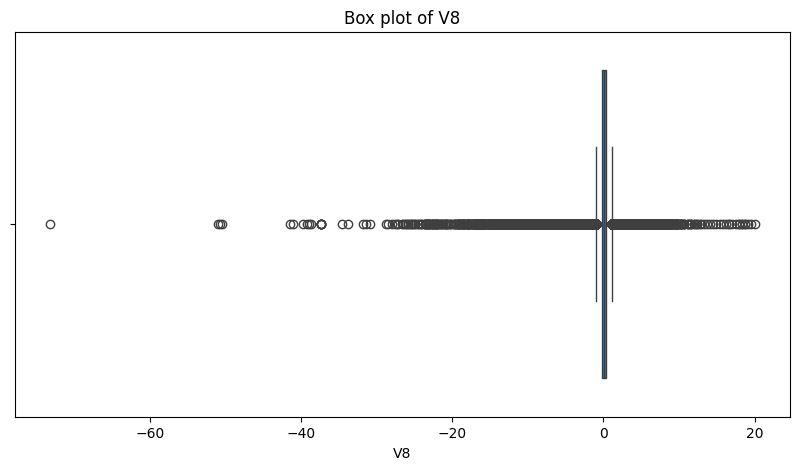

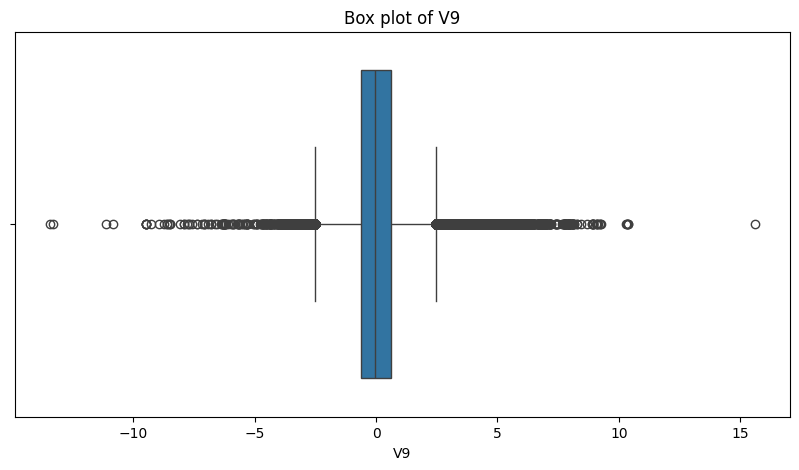

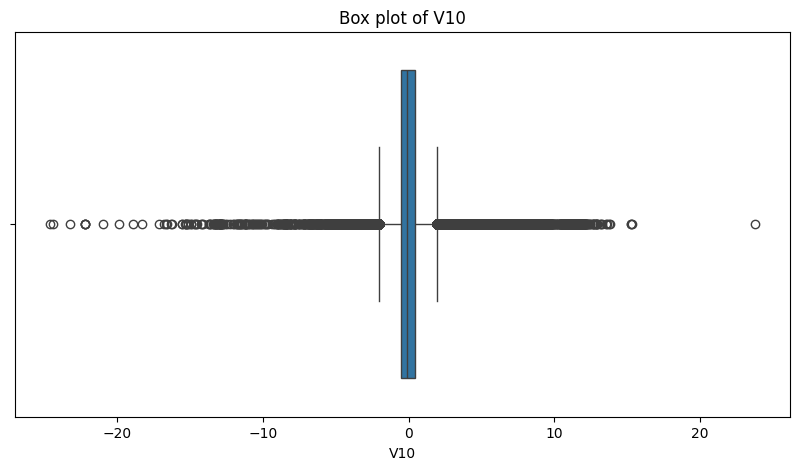

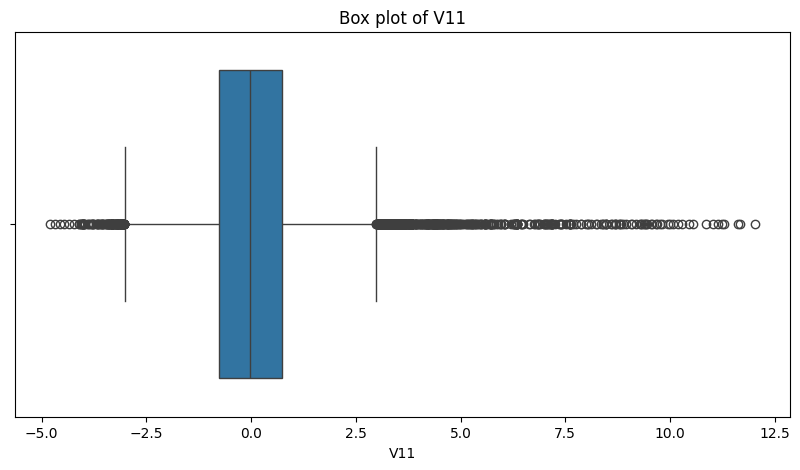

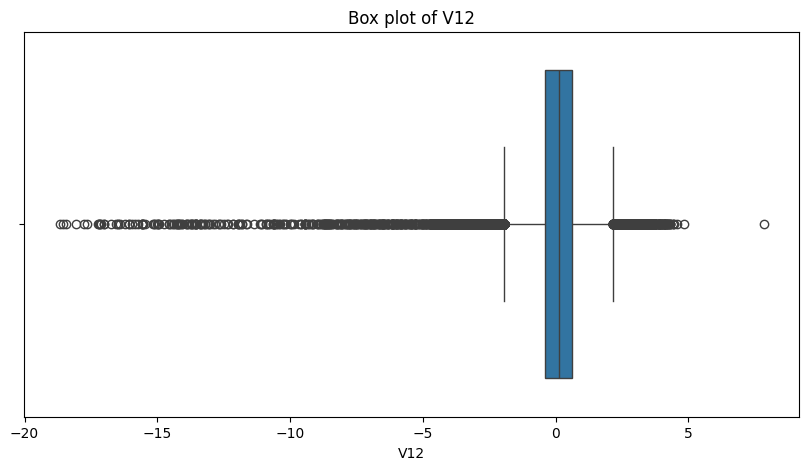

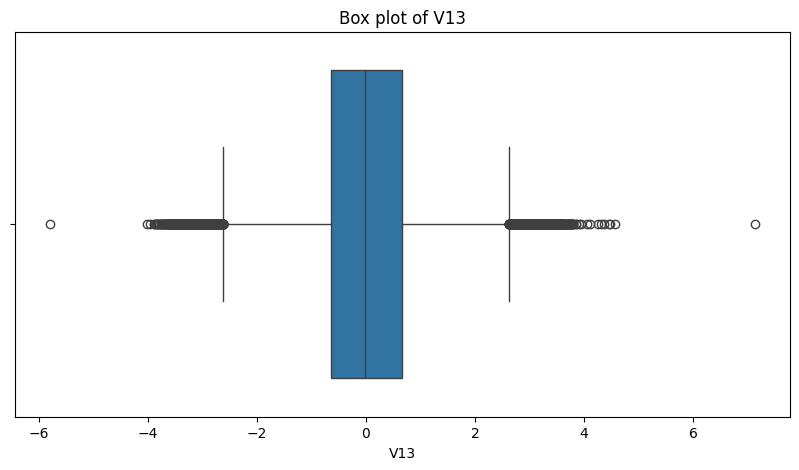

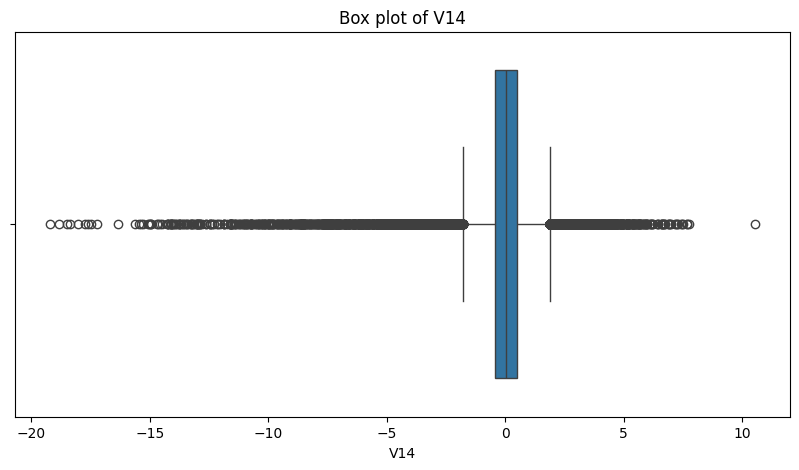

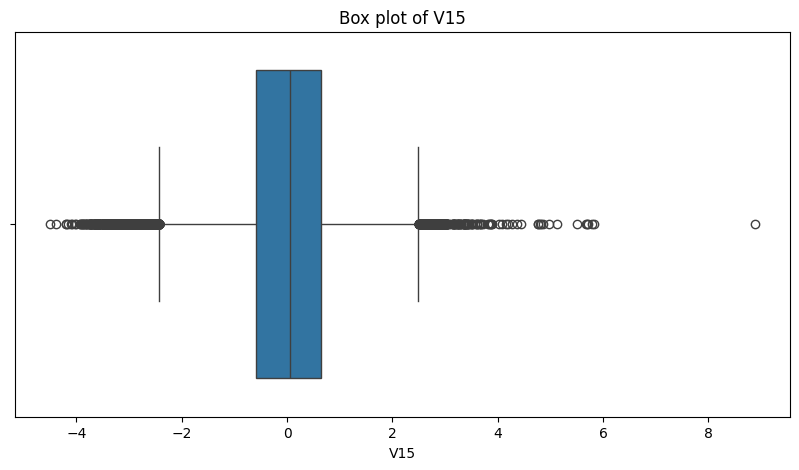

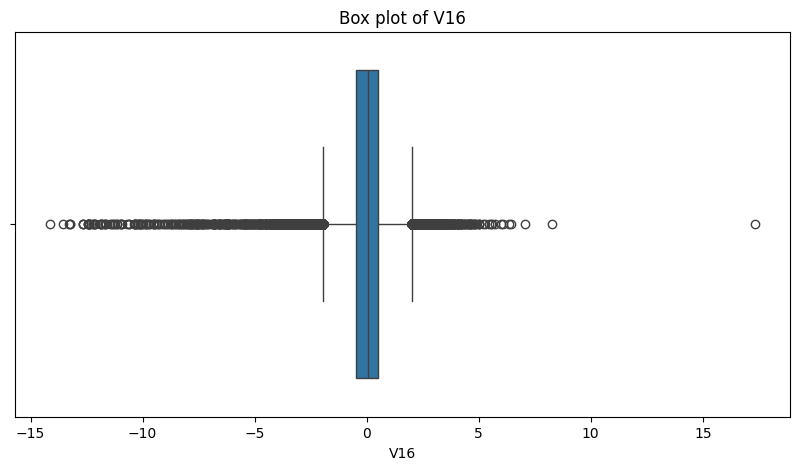

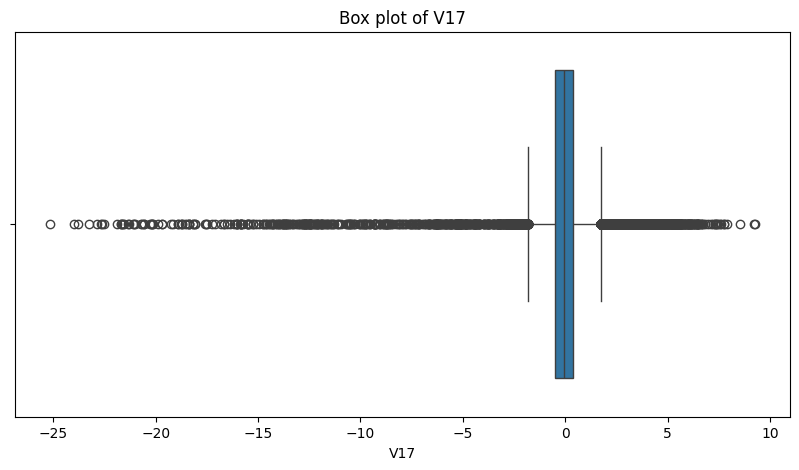

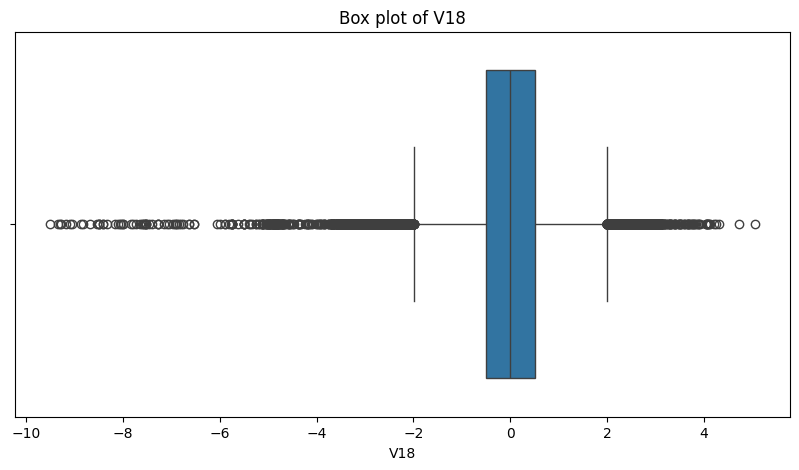

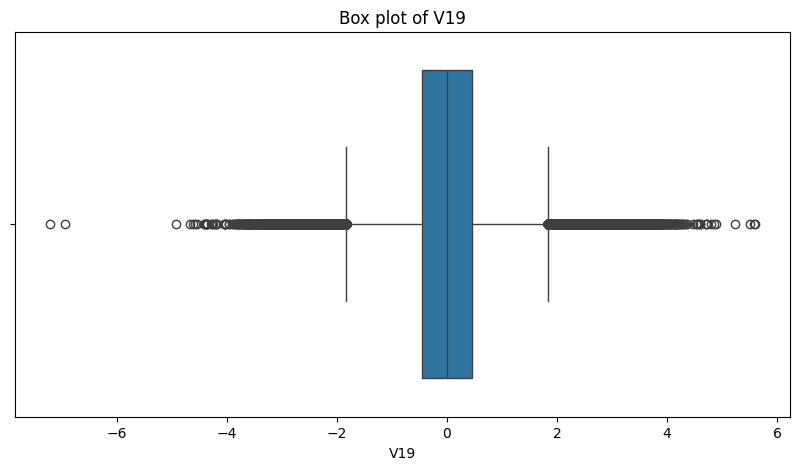

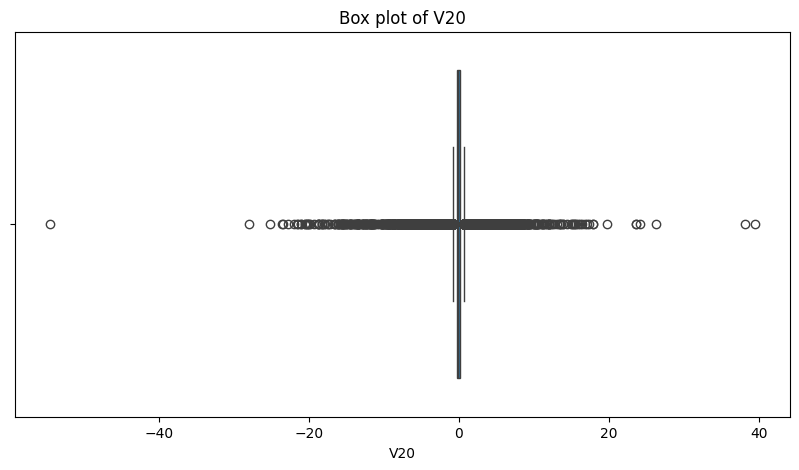

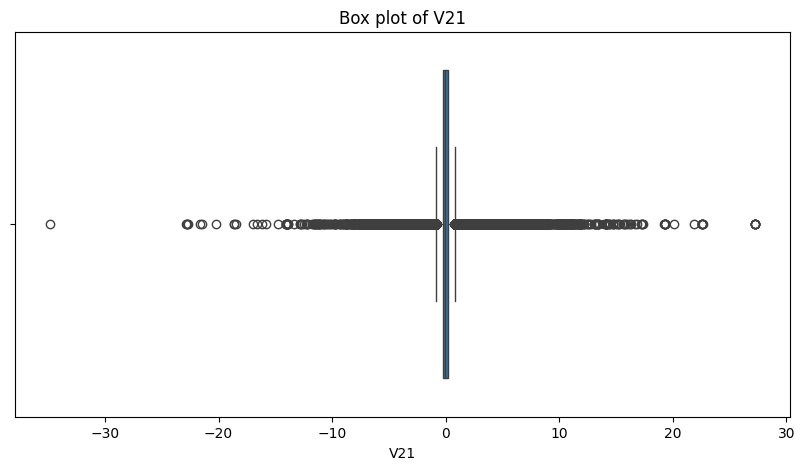

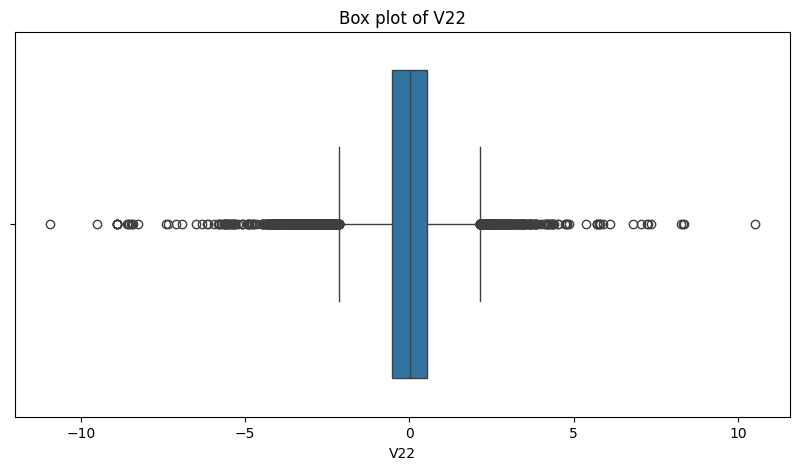

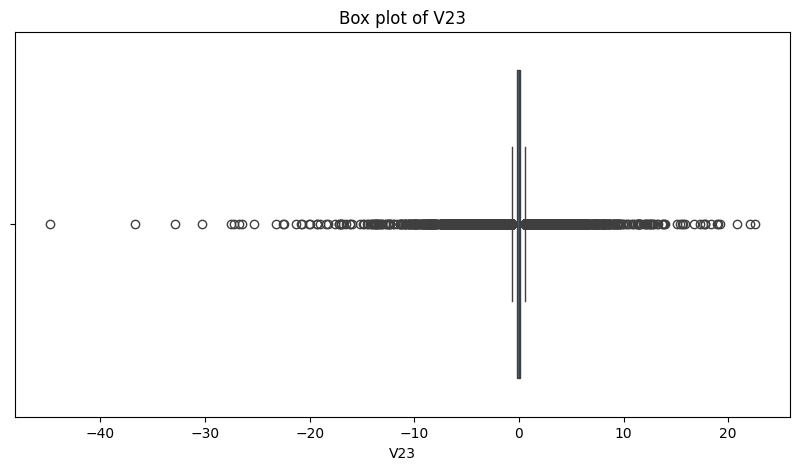

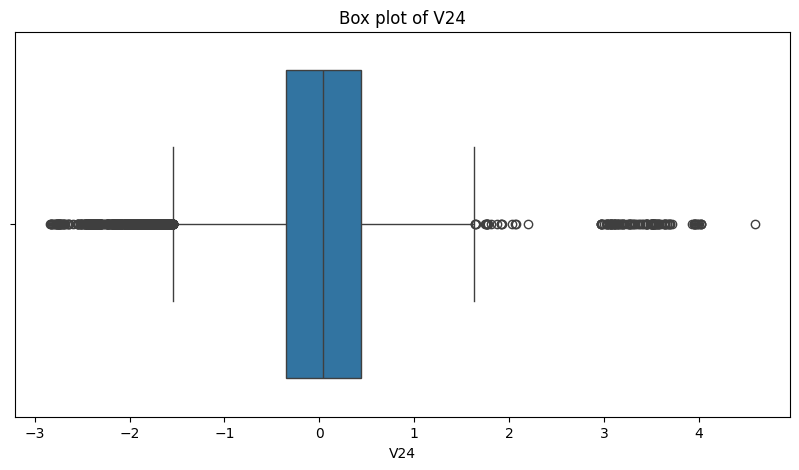

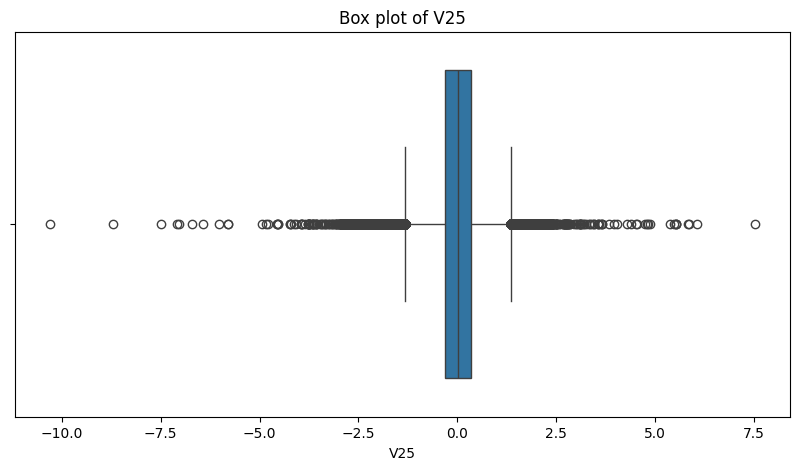

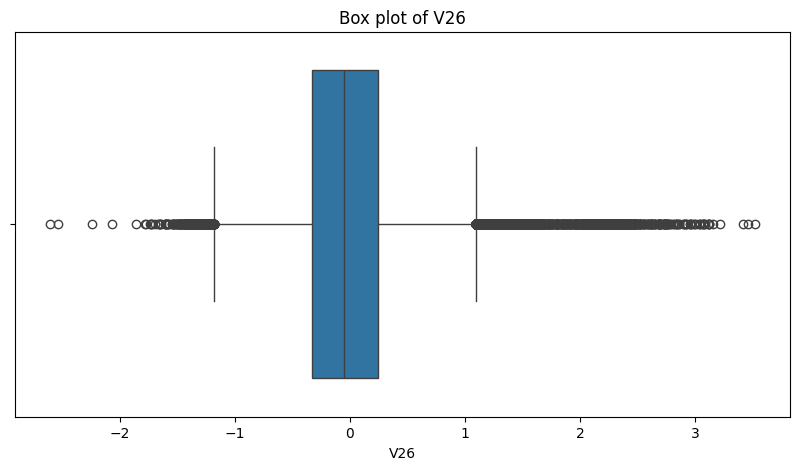

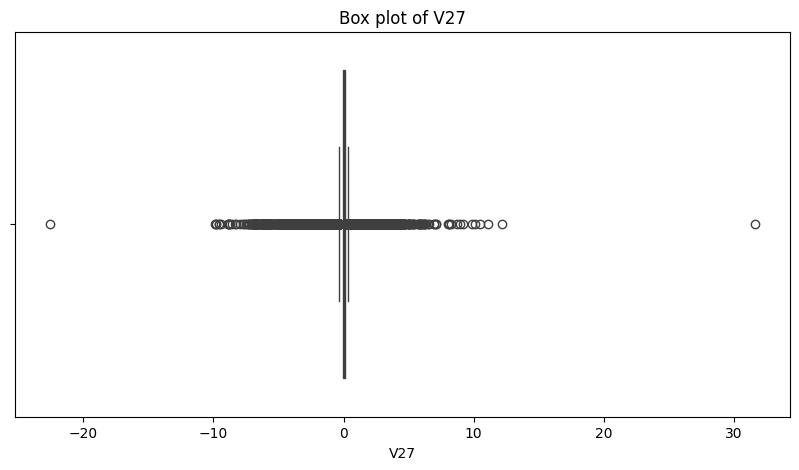

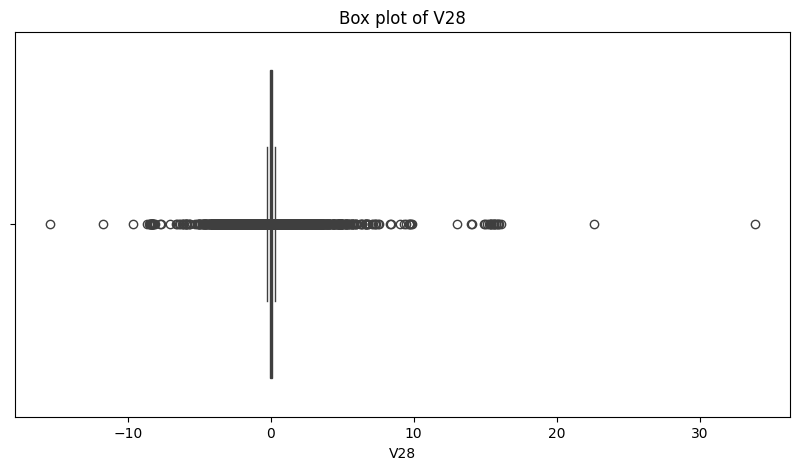

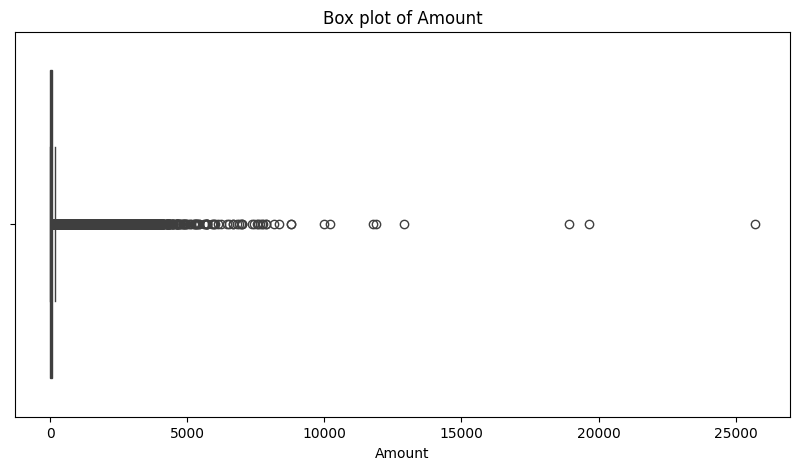

In [5]:
#check for outliers with box plots, need to see distribution of each feature
for feature in numeric_features:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=cc_data[feature])
    plt.title(f"Box plot of {feature}")
    plt.show()

Part 2. [10 pts] Check the class balance, choose an evaluation metric, and justify the choice. 

This a is a very imbalanced dataset with 492 positives and 284315 negatives. In this case since we have such a large class imbalance and false negatives are significantly more costly than false positives I would select using the F2-Score which focused on recall rather than precision. F1 treats precision and recall equally, F2 weights recall more heavily.

In [6]:
#check for class imbalance
class_counts = cc_data["Class"].value_counts()
print(class_counts)

Class
0    284315
1       492
Name: count, dtype: int64


Part 3. [10 pts] Justify if you need normalization or standardization. Complete pre-processing. 

Based on the box plots alone standardization would be the best choice. Since we have a few outliers normalization would compress the rest of the values into a very narrow range limiting their contribution to learning.

We are going to need to drop time as it is monotonically increasing and does not have any correlation making it effectively dead weight. 

In [7]:
#check range of each feature
for feature in numeric_features:
    min_value = cc_data[feature].min()
    max_value = cc_data[feature].max()
    std_value = cc_data[feature].std()
    rng_value = max_value - min_value
    print(f"{feature}: min={min_value}, max={max_value}",f" range={rng_value}", f" std={std_value}")

#drop time 
cc_data = cc_data.drop(columns=["Time"]) #may revisit this later
#standardize the rest of the features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(cc_data.drop(columns=["Class"])) #feature scaling
#setup our dependent and independent variables
y = cc_data["Class"].values

Time: min=0.0, max=172792.0  range=172792.0  std=47488.14453125
V1: min=-56.407508850097656, max=2.454930067062378  range=58.8624382019043  std=1.9586957693099976
V2: min=-72.71572875976562, max=22.057729721069336  range=94.7734603881836  std=1.651308536529541
V3: min=-48.32558822631836, max=9.382558822631836  range=57.70814514160156  std=1.5162550210952759
V4: min=-5.683171272277832, max=16.875343322753906  range=22.558513641357422  std=1.4158685207366943
V5: min=-113.7433090209961, max=34.801666259765625  range=148.54498291015625  std=1.3802467584609985
V6: min=-26.160505294799805, max=73.30162811279297  range=99.4621353149414  std=1.3322710990905762
V7: min=-43.55724334716797, max=120.58949279785156  range=164.146728515625  std=1.2370935678482056
V8: min=-73.21672058105469, max=20.0072078704834  range=93.22393035888672  std=1.1943528652191162
V9: min=-13.434066772460938, max=15.59499454498291  range=29.02906036376953  std=1.0986320972442627
V10: min=-24.5882625579834, max=23.7451362

Part 4. [10 pts] Split the dataset 50-50 for training and testing. Then, without any tree pruning or 
regularization, run classifiers of the following types:  
• SVC 
• DecisionTreeClassifier 
• MLPClassifier 
• RandomForest 
Report each one’s classification performance.  

In [22]:
from sklearn.model_selection import train_test_split 
from sklearn.metrics import classification_report, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, stratify=y, random_state=42) #50/50 test train split, need to stratify since the class imbalance that bad
#keeping random state set for reproducibility


#import the various models
from sklearn.svm import LinearSVC as SVM
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

#using F2 score for evaluation in this case
from sklearn.metrics import fbeta_score


#need to define the models
models = {
    "SVM": SVM(), 
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "MLP": MLPClassifier(max_iter=1000, random_state=42) #need to increase max iterations for convergence
}

#create a dictionary for the results
baseline_results = {}

#train and evaluate each model, evaluate with F2 score and confusion matrix
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    f2 = fbeta_score(y_test, y_pred, beta=2)    
    cm = confusion_matrix(y_test, y_pred, labels=[1,0]) # confusion matrix with positive class first, makes it easier to read
    recall = cm[0, 0] / (cm[0, 0] + cm[0, 1]) if (cm[0, 0] + cm[0, 1]) > 0 else 0 # calculate recall from confusion matrix
    baseline_results[name] = {
        'f2_score': f2,
        'recall': recall,
        'cm': cm
    }
    print(f"{name} Recall: {recall:.4f}")
    print(f"{name} F2 Score: {f2:.4f}")
    print(f"{name} Confusion Matrix:\n{cm}\n\n")

SVM Recall: 0.5813
SVM F2 Score: 0.6234
SVM Confusion Matrix:
[[   143    103]
 [    20 142138]]


Decision Tree Recall: 0.7561
Decision Tree F2 Score: 0.7536
Decision Tree Confusion Matrix:
[[   186     60]
 [    64 142094]]


Random Forest Recall: 0.7480
Random Forest F2 Score: 0.7830
Random Forest Confusion Matrix:
[[   184     62]
 [     7 142151]]


MLP Recall: 0.6992
MLP F2 Score: 0.7363
MLP Confusion Matrix:
[[   172     74]
 [    12 142146]]




Part 5. [10 pts] Now use tree pruning and/or regularization to run classifiers of the following types:  
• SVC 
• DecisionTreeClassifier 
• MLPClassifier 
(Hint: you might use GridSearchCV to optimize the regularization parameters, or simply run 
a few pilot tests). Report each one’s classification performance. Make sure to use the same 
subsets as above to train and test. 

In [24]:
#lets set up the same models but with regularization parameters for grid search
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer
f2_scorer = make_scorer(fbeta_score, beta=2) # using make_scorer to create a custom scorer for F2 score for use in GridSearchCV


paramter_grid = {
    "SVM":{
        'model': SVM(), 
        'params': {
            'C': [0.1, 1, 10], # regularization parameter
        }
    },
    'Decision Tree': {
        
        'model': DecisionTreeClassifier(random_state=42), # adding cost complexity pruning with a small alpha
        'params': {
            'ccp_alpha': [0.0, 0.001, 0.01, 0.1], # trying different values for cost complexity pruning
            'max_depth': [None,3,5,7], # maximum depth of the tree
        }
    },
    'MLP': {
        'model': MLPClassifier(max_iter=1000, random_state=42),
        'params': {
            'hidden_layer_sizes': [(50,), (100,), (50,50)], # different architectures
            'activation': ['logistic', 'relu'], # different activation functions
            'alpha': [0.0001, 0.001, 0.01] # trying out different L2 parameters
        }
    }
}

#run grid search for each model
best_models = {}


#going to need strified splitting
from sklearn.model_selection import StratifiedKFold
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


for name, config in paramter_grid.items():
    print(f'Grid search for {name}...')
    grid_search = GridSearchCV(
        config['model'],
        config['params'],
        scoring=f2_scorer, # using F2 score for evaluation
        cv=cv_strat,
        n_jobs=-1,
        verbose=1
    )
    grid_search.fit(X_train, y_train)

    #check best parameters on the test set
    y_pred = grid_search.best_estimator_.predict(X_test)
    f2 = fbeta_score(y_test, y_pred, beta=2)
    cm = confusion_matrix(y_test, y_pred, labels=[1,0])
    recall = cm[0, 0] / (cm[0, 0] + cm[0, 1]) if (cm[0, 0] + cm[0, 1]) > 0 else 0

    best_models[name] = {
        'best_parameters': grid_search.best_params_,
        'best_f2_score': grid_search.best_score_,
        'test_f2_score': f2,
        'recall': recall,
        'confusion_matrix': cm
    }

#print results of the grid search
for name, result in best_models.items():
    print(f"{name} Best Parameters: {result['best_parameters']}")
    print(f"{name} Best F2 Score (CV): {result['best_f2_score']:.4f}")
    print(f"{name} Test F2 Score: {result['test_f2_score']:.4f}")
    print(f"{name} Recall: {result['recall']:.4f}")
    print(f"{name} Confusion Matrix:\n{result['confusion_matrix']}\n\n")



Grid search for SVM...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Grid search for Decision Tree...
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Grid search for MLP...
Fitting 5 folds for each of 18 candidates, totalling 90 fits
SVM Best Parameters: {'C': 1}
SVM Best F2 Score (CV): 0.6491
SVM Test F2 Score: 0.6234
SVM Recall: 0.5813
SVM Confusion Matrix:
[[   143    103]
 [    20 142138]]


Decision Tree Best Parameters: {'ccp_alpha': 0.0, 'max_depth': 7}
Decision Tree Best F2 Score (CV): 0.7750
Decision Tree Test F2 Score: 0.7862
Decision Tree Recall: 0.7683
Decision Tree Confusion Matrix:
[[   189     57]
 [    29 142129]]


MLP Best Parameters: {'activation': 'relu', 'alpha': 0.001, 'hidden_layer_sizes': (50,)}
MLP Best F2 Score (CV): 0.8290
MLP Test F2 Score: 0.7760
MLP Recall: 0.7520
MLP Confusion Matrix:
[[   185     61]
 [    23 142135]]




In [25]:
import pandas as pd

comparison = []

for model in baseline_results.keys():
    if model not in best_models:
        continue  # skip models that were not tuned
    comparison.append({
        "Model": model,
        "Baseline F2 Score": baseline_results[model]['f2_score'],
        "Baseline Recall": baseline_results[model]['recall'],

        "Tuned F2 Score": best_models[model]['test_f2_score'],
        "Tuned Recall": best_models[model]['recall'],

        "Change in F2 Score": best_models[model]['test_f2_score'] - baseline_results[model]['f2_score'],
        "Change in Recall": best_models[model]['recall'] - baseline_results[model]['recall'],
    })
comparison_df = pd.DataFrame(comparison)
print(comparison_df)

           Model  Baseline F2 Score  Baseline Recall  Tuned F2 Score  \
0            SVM           0.623365         0.581301        0.623365   
1  Decision Tree           0.753647         0.756098        0.786190   
2            MLP           0.736301         0.699187        0.776007   

   Tuned Recall  Change in F2 Score  Change in Recall  
0      0.581301            0.000000          0.000000  
1      0.768293            0.032543          0.012195  
2      0.752033            0.039705          0.052846  


Part 5: Results of various models

           Model  Baseline F2 Score  Baseline Recall  Tuned F2 Score    Tuned Recall  Change in F2 Score  Change in Recall  
            SVM           0.623365         0.581301        0.623365      0.581301            0.000000          0.000000
  Decision Tree           0.753647         0.756098        0.786190      0.768293            0.032543          0.012195
            MLP           0.736301         0.699187        0.776007      0.752033            0.039705          0.052846 


The model that showed the most improvement in both F2 score and Recall was the MLP. There was no change in the SVM as it ended up using the same parameters as the untuned version. There were slight improvements in the decision tree, even when it was given no max depth it found that a tree depth of 7 was optimal and kept alpha to 0 meaning we didn't need to prune the tree.

Part 6. [30 pts] Script a PyTorch neural network with a hidden layer. (You could also experiment 
with 2 hidden layers, with sizes between 20 and 40). Report its classification performance, 
using the same 50-50 subsets. (Expect a similar performance to the neural network in Q5.) 

In [11]:
%matplotlib inline
import matplotlib.pyplot as plt


import torch

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.10.0+cu126
CUDA available: True


In [12]:

from sklearn.utils.class_weight import compute_class_weight # compute class weights for the imbalanced dataset
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train), 
    y=y_train
)
class_weights = torch.FloatTensor(class_weights) # convert class weights to a PyTorch tensor for use in the loss function

class PyTorchMLP(torch.nn.Module):  # One hidden layer
    def __init__(self, n_hidden1=40,n_hidden2=20, epochs=100, eta=0.001, minibatch_size=50, seed=42): #needed to set random see the same as the rest of the code for reproducibility
        super().__init__()
        self.random = np.random.RandomState(seed)  # shuffle mini batches
        self.n_hidden1 = n_hidden1  # size of the hidden layer
        self.n_hidden2 = n_hidden2 # size of the second hidden layer
        self.epochs = epochs  # number of iterations
        self.eta = eta  # learning rate
        self.minibatch_size = minibatch_size  # size of training batch
        self.loss_func = torch.nn.CrossEntropyLoss(weight=class_weights) # adding class weights to the loss function to help with imbalance
        self.model = None

    def init_layers(self, _M:int, _K:int) -> None:
        # data structure
        self.model = torch.nn.Sequential(
            torch.nn.Linear(_M, self.n_hidden1), # input layer to hidden layer
            torch.nn.ReLU(),
            torch.nn.Linear(self.n_hidden1, self.n_hidden2), # hidden layer 1 to hidden layer 2
            torch.nn.ReLU(),
            torch.nn.Linear(self.n_hidden2, _K), # hidden layer 2 to output layer
        )
    
    def predict(self, _X):
        _X = torch.FloatTensor(_X)
        assert self.model is not None
        self.model.eval()
        with torch.no_grad():
            y_pred = np.argmax(self.model(_X), axis=1)
        self.model.train()
        return y_pred.numpy()

    def fit(self, _X_train, _y_train, info=False):
        import sys
        _X_train, _y_train = torch.FloatTensor(_X_train), torch.LongTensor(_y_train)
        n_features= _X_train.shape[1]
        n_output= len(np.unique(_y_train))  # number of class labels
        
        self.init_layers(n_features, n_output)
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=self.eta)  # Swapped to Adaam optimizer for this dataset

        for i in range(self.epochs):
            indices = np.arange(_X_train.shape[0])
            self.random.shuffle(indices)  # shuffle the data each epoch

            for start_idx in range(0, indices.shape[0] - self.minibatch_size + 1, self.minibatch_size):
                batch_idx = indices[start_idx:start_idx + self.minibatch_size]
                self.optimizer.zero_grad()
                
                net_out = self.model(_X_train[batch_idx])
                
                loss = self.loss_func(net_out, _y_train[batch_idx])
                loss.backward()
                self.optimizer.step()
                
                if info:
                    sys.stderr.write(f"\r{i+1:03d} Loss: {loss.item():6.5f}")
                    sys.stderr.flush()
        return self

In [13]:
%time
#Run the PytorchMLP on the data we have already prepared in previous cell
pytorch_mlp = PyTorchMLP(n_hidden1=40, n_hidden2=20, epochs=100, eta=0.001, minibatch_size=50, seed=42)
pytorch_mlp.fit(X_train, y_train, info=True)
y_pred = pytorch_mlp.predict(X_test)
f2 = fbeta_score(y_test, y_pred, beta=2)
cm = confusion_matrix(y_test, y_pred, labels=[1,0])
recall = cm[0, 0] / (cm[0, 0] + cm[0, 1]) if (cm[0, 0] + cm[0, 1]) > 0 else 0
print(f"Pytorch MLP F2 Score: {f2:.4f}")
print(f"Pytorch MLP Recall: {recall:.4f}")
print(f"Pytorch MLP Confusion Matrix:\n{cm}\n\n")


CPU times: total: 0 ns
Wall time: 7.87 μs


100 Loss: 0.000000

Pytorch MLP F2 Score: 0.7430
Pytorch MLP Recall: 0.7967
Pytorch MLP Confusion Matrix:
[[   196     50]
 [   139 142019]]




First time I ran this I used the original coding on the loss function and it did not detect any fraud. Had to add class weights to loss function. Also added the optimizer function which uses Adam. 
Initial trial:
001 Loss: 0.83722
001 Loss: 0.0000035
CPU times: total: 0 ns
Wall time: 3.34 μs
100 Loss: 0.0000052
Pytorch MLP F2 Score: 0.6378
Pytorch MLP Recall: 0.6098
Pytorch MLP Confusion Matrix:
[[   150     96]
 [    42 142116]]

With Adam:
001 Loss: 0.25499
CPU times: total: 0 ns
Wall time: 3.81 μs
100 Loss: 0.000006
Pytorch MLP F2 Score: 0.7337
Pytorch MLP Recall: 0.7480
Pytorch MLP Confusion Matrix:
[[   184     62]
 [    86 142072]]

In [14]:
# A derived class to have Dropout
class MLP2(PyTorchMLP):
    def init_layers(self, _M, _K):
        self.model = torch.nn.Sequential(
            torch.nn.Linear(_M, self.n_hidden1),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(self.n_hidden1, self.n_hidden2),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(self.n_hidden2, _K),
        )

In [15]:
#Run Dropout MLP on same dataset
pytorch_mlp_dropout = MLP2(n_hidden1=40, n_hidden2=20, epochs=100, eta=0.001, minibatch_size=50, seed=42)
pytorch_mlp_dropout.fit(X_train, y_train, info=True)
y_pred = pytorch_mlp_dropout.predict(X_test)
f2 = fbeta_score(y_test, y_pred, beta=2)
cm = confusion_matrix(y_test, y_pred, labels=[1,0])
recall = cm[0, 0] / (cm[0, 0] + cm[0, 1]) if (cm[0, 0] + cm[0, 1]) > 0 else 0
print(f"Pytorch MLP with Dropout F2 Score: {f2:.4f}")
print(f"Pytorch MLP with Dropout Recall: {recall:.4f}")
print(f"Pytorch MLP with Dropout Confusion Matrix:\n{cm}\n\n")

100 Loss: 0.000005

Pytorch MLP with Dropout F2 Score: 0.7260
Pytorch MLP with Dropout Recall: 0.7561
Pytorch MLP with Dropout Confusion Matrix:
[[   186     60]
 [   111 142047]]




Part 7. [10 pts] Add dropout to the PyTorch neural network and repeat the previous step. Note that 
a robust model is always preferred even with a performance comparable to Q5. or Q6.’s 
neural networks. Why? 
With Dropout: 
100 Loss: 0.000007
Pytorch MLP with Dropout F2 Score: 0.7212
Pytorch MLP with Dropout Recall: 0.7927
Pytorch MLP with Dropout Confusion Matrix:
[[   195     51]
 [   173 141985]]



In [16]:
from sklearn.model_selection import cross_val_score

f2_scorer = make_scorer(fbeta_score, beta=2)

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

cross_val = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

random_forest_scores = cross_val_score(random_forest, X_train, y_train, cv=cross_val, scoring=f2_scorer)
random_forest.fit(X_train, y_train)
y_pred_rf = random_forest.predict(X_test)
f2_rf = fbeta_score(y_test, y_pred_rf, beta=2)
cm = confusion_matrix(y_test, y_pred_rf, labels=[1,0])
recall = cm[0, 0] / (cm[0, 0] + cm[0, 1]) if (cm[0, 0] + cm[0, 1]) > 0 else 0

print(f"Random Forest Cross-Validated F2 Scores: {random_forest_scores}")
print(f"Random Forest Mean Cross-Validated F2 Score: {random_forest_scores.mean():.4f}")
print(f"Random Forest Standard Deviation of Cross-Validated F2 Scores: {random_forest_scores.std():.4f}")
print(f"Random Forest F2 Score: {f2_rf:.4f}")
print(f"Random Forest Recall: {recall:.4f}")
print(f"Random Forest Confusion Matrix:\n{cm}\n\n")

Random Forest Cross-Validated F2 Scores: [0.88709677 0.79166667 0.86065574 0.68965517 0.85470085 0.83333333
 0.71428571 0.75630252 0.84       0.83333333]
Random Forest Mean Cross-Validated F2 Score: 0.8061
Random Forest Standard Deviation of Cross-Validated F2 Scores: 0.0626
Random Forest F2 Score: 0.7830
Random Forest Recall: 0.7480
Random Forest Confusion Matrix:
[[   184     62]
 [     7 142151]]




In [17]:
#If we want to run the same cross validation for the MLP and DropoutMLP we are going to need a wrapper
from sklearn.base import BaseEstimator, ClassifierMixin

class PyWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, n_hidden1=40, n_hidden2=20, epochs=100, eta=0.001, minibatch_size=50, seed=42, dropout=False):
        self.n_hidden1 = n_hidden1
        self.n_hidden2 = n_hidden2
        self.epochs = epochs
        self.eta = eta
        self.minibatch_size = minibatch_size
        self.seed = seed
        self.dropout = dropout
        self.model = None

    def fit(self, X, y):
        if self.dropout:
            self.model = MLP2(n_hidden1=self.n_hidden1, n_hidden2=self.n_hidden2, epochs=self.epochs, eta=self.eta, minibatch_size=self.minibatch_size, seed=self.seed)
        else:
            self.model = PyTorchMLP(n_hidden1=self.n_hidden1, n_hidden2=self.n_hidden2, epochs=self.epochs, eta=self.eta, minibatch_size=self.minibatch_size, seed=self.seed)
        self.model.fit(X, y)
        return self

    def predict(self, X):
        return self.model.predict(X)
#Now we can run and get cross val scores for regular NN and Dropout NN
#Cross val for regular NN
pytorch_wrapper = PyWrapper()
py_scores = cross_val_score(pytorch_wrapper, X_train, y_train, cv=cross_val, scoring=f2_scorer)
pytorch_wrapper.fit(X_train, y_train) # fit the model on the training data to get predictions for the test set
y_pred_nn = pytorch_wrapper.predict(X_test)
f2_nn = fbeta_score(y_test, y_pred_nn, beta=2)
cm = confusion_matrix(y_test, y_pred_nn, labels=[1,0])
recall = cm[0, 0] / (cm[0, 0] + cm[0, 1]) if (cm[0, 0] + cm[0, 1]) > 0 else 0
print(f"Pytorch MLP Cross-Validated F2 Scores: {py_scores}")
print(f"Pytorch MLP Mean Cross-Validated F2 Score: {py_scores.mean():.4f}")
print(f"Pytorch MLP Standard Deviation of Cross-Validated F2 Scores: {py_scores.std():.4f}")
print(f"Pytorch MLP F2 Score: {f2_nn:.4f}")
print(f"Pytorch MLP Recall: {recall:.4f}")
print(f"Pytorch MLP Confusion Matrix:\n{cm}\n\n")


#for dropout NN
pytorch_dropout_wrapper = PyWrapper(dropout=True)
py_dropout_scores = cross_val_score(pytorch_dropout_wrapper, X_train, y_train, cv=cross_val, scoring=f2_scorer)
pytorch_dropout_wrapper.fit(X_train, y_train) # fit the model on the training data to get predictions for the test set
y_pred_dropout = pytorch_dropout_wrapper.predict(X_test)
f2_dropout = fbeta_score(y_test, y_pred_dropout, beta=2)
cm = confusion_matrix(y_test, y_pred_dropout, labels=[1,0])
recall = cm[0, 0] / (cm[0, 0] + cm[0, 1]) if (cm[0, 0] + cm[0, 1]) > 0 else 0
print(f"Pytorch MLP with Dropout Cross-Validated F2 Scores: {py_dropout_scores}")
print(f"Pytorch MLP with Dropout Mean Cross-Validated F2 Score: {py_dropout_scores.mean():.4f}")
print(f"Pytorch MLP with Dropout Standard Deviation of Cross-Validated F2 Scores: {py_dropout_scores.std():.4f}")
print(f"Pytorch MLP with Dropout F2 Score: {f2_dropout:.4f}")
print(f"Pytorch MLP with Dropout Recall: {recall:.4f}")
print(f"Pytorch MLP with Dropout Confusion Matrix:\n{cm}\n\n")




Pytorch MLP Cross-Validated F2 Scores: [0.78014184 0.86466165 0.75       0.73076923 0.82706767 0.7751938
 0.67460317 0.72847682 0.82733813 0.75539568]
Pytorch MLP Mean Cross-Validated F2 Score: 0.7714
Pytorch MLP Standard Deviation of Cross-Validated F2 Scores: 0.0535
Pytorch MLP F2 Score: 0.7236
Pytorch MLP Recall: 0.7683
Pytorch MLP Confusion Matrix:
[[   189     57]
 [   133 142025]]


Pytorch MLP with Dropout Cross-Validated F2 Scores: [0.79136691 0.90551181 0.78740157 0.69343066 0.85365854 0.73529412
 0.68376068 0.71428571 0.83333333 0.80769231]
Pytorch MLP with Dropout Mean Cross-Validated F2 Score: 0.7806
Pytorch MLP with Dropout Standard Deviation of Cross-Validated F2 Scores: 0.0693
Pytorch MLP with Dropout F2 Score: 0.7496
Pytorch MLP with Dropout Recall: 0.7642
Pytorch MLP with Dropout Confusion Matrix:
[[   188     58]
 [    82 142076]]




Part 8: [10 pts] Train a Random Forest classifier with a 10-fold CV; revisit the two PyTorch neural 
networks from Q6. and Q7. And train them with a 10-fold CV. Comment on the results. 


Random Forest Mean Cross-Validated F2 Score: 0.8061
Random Forest Standard Deviation of Cross-Validated F2 Scores: 0.0626
Random Forest F2 Score: 0.7830
Random Forest Recall: 0.7480
Random Forest Confusion Matrix:
[[   184     62]
 [     7 142151]]



Pytorch MLP Mean Cross-Validated F2 Score: 0.7714
Pytorch MLP Standard Deviation of Cross-Validated F2 Scores: 0.0535
Pytorch MLP F2 Score: 0.7236
Pytorch MLP Recall: 0.7683
Pytorch MLP Confusion Matrix:
[[   189     57]
 [   133 142025]]



Pytorch MLP with Dropout Mean Cross-Validated F2 Score: 0.7806
Pytorch MLP with Dropout Standard Deviation of Cross-Validated F2 Scores: 0.0693
Pytorch MLP with Dropout F2 Score: 0.7496
Pytorch MLP with Dropout Recall: 0.7642
Pytorch MLP with Dropout Confusion Matrix:
[[   188     58]
 [    82 142076]]